# Advanced Data Preparation with Python (Apartment Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped rental apartment data from Zurich. It is an exercise: complete the empty code cells. The solution is in advanced_data_preparation_apartment_data_solution.ipynb. 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [108]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/python_data_preparation


## Importing data

In [109]:
# Read the data to a pandas data frame
df = pd.read_csv('./Data/apartments_data_zuerich.csv',
                 sep=',',
                 encoding='utf-8')

# Show first records of data frame
df.head()

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«Gemütliche Wohnung im Grünen»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86..."
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,..."
2,1693998201-3,https://www.immoscout24.ch/de/immobilien/miete...,"19 m², CHF 2686.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 2686.—,«Studio Apartment Junior Balcony»,"19 m², CHF 2686.—Cramerstrasse 8-12, 8004 Züri..."
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 Bedroom Apartment Senior Balcony»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,..."
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 Bedroom Apartment Junior Terrace»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8..."


## Count number of rows and columns in the data frame

In [110]:
# Dimension (rows, columns)
df.info()
print(df.shape)


# Number of rows
print(df.shape[0])

# Number of columns
print(df.shape[1])

<class 'pandas.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   web-scraper-order      1008 non-null   str  
 1   web-scraper-start-url  1008 non-null   str  
 2   rooms_area_price_raw   1008 non-null   str  
 3   address_raw            1008 non-null   str  
 4   price_raw              1008 non-null   str  
 5   description_raw        1008 non-null   str  
 6   text_raw               1008 non-null   str  
dtypes: str(7)
memory usage: 55.3 KB
(1008, 7)
1008
7


## Get data types (raw-format from web scraper)

In [111]:
# Get data types (note that in pandas, a string is referred to as 'object')
datatypes = df.dtypes
print(datatypes)

web-scraper-order        str
web-scraper-start-url    str
rooms_area_price_raw     str
address_raw              str
price_raw                str
description_raw          str
text_raw                 str
dtype: object


## Extract information from raw data using regular expressions (regex)

### Extract number of rooms

In [112]:
# Extract values from 'rooms_area_price_raw' strings
rooms = []
for s in df['rooms_area_price_raw']:
    m = re.search(r'(\d+(?:[.,]\d+)?)\s*Zimmer', str(s))   # number right before "Zimmer"
    if m:
        rooms.append(float(m.group(1).replace(',', '.')))   # '3,5' -> 3.5
    else:
        rooms.append(None)                                   # no rooms given -> missing (adds NaN)

df['rooms'] = pd.Series(rooms, index=df.index)              # same index as df, length must match
df[['rooms_area_price_raw', 'rooms']].head(7)

# Save as new variable in the pandas data frame


# Show first records of data frame


,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0
5,"34 m², CHF 3205.—",NaN
6,"25 m², CHF 3308.—",NaN


### Extract living area

In [113]:
# Extract values from 'rooms_area_price_raw' strings
area = []
for s in df['rooms_area_price_raw']:
    m = re.search(r'(\d+)(\s*m²)', str(s))   # number right before "Zimmer"
    if m:
        area.append(float(m.group(1))) #group 1 -> first brackets (\d+) /// group 0 would return the whole thing inclunding m^2
    else:
        area.append(None)                                   # no area given -> missing (adds NaN)

df['area'] = pd.Series(area, index=df.index)              # same index as df, length must match
df[['rooms_area_price_raw', 'rooms', 'area']].head(7)

# Save as new variable in the pandas data frame


# Show first records of data frame


,rooms_area_price_raw,rooms,area
0,"3 Zimmer, 49 m², CHF 1441.—",3.0,49.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5,65.0
2,"19 m², CHF 2686.—",NaN,19.0
3,"2 Zimmer, 54 m², CHF 4853.—",2.0,54.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0,49.0
5,"34 m², CHF 3205.—",NaN,34.0
6,"25 m², CHF 3308.—",NaN,25.0


### Extract rental price

In [114]:
# Extract values from 'price_raw' strings
price_chf = []
for s in df['price_raw']:
    m = re.search(r'(\d+)', str(s))   # number right before "Zimmer"
    if m:
        price_chf.append(float(m.group(0))) #group 1 -> first brackets (\d+) /// group 0 would return the whole thing inclunding m^2
    else:
        price_chf.append(None)                                   # no area given -> missing (adds NaN)

df['price_chf'] = pd.Series(price_chf, index=df.index)              # same index as df, length must match
df[['rooms_area_price_raw', 'price_raw', 'rooms', 'area', 'price_chf']].head(7)

# Save as new variable in the pandas data frame


# Show first records of data frame


,rooms_area_price_raw,price_raw,rooms,area,price_chf
0,"3 Zimmer, 49 m², CHF 1441.—",CHF 1441.—,3.0,49.0,1441.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",CHF 1850.—,3.5,65.0,1850.0
2,"19 m², CHF 2686.—",CHF 2686.—,NaN,19.0,2686.0
3,"2 Zimmer, 54 m², CHF 4853.—",CHF 4853.—,2.0,54.0,4853.0
4,"2 Zimmer, 49 m², CHF 4335.—",CHF 4335.—,2.0,49.0,4335.0
5,"34 m², CHF 3205.—",CHF 3205.—,NaN,34.0,3205.0
6,"25 m², CHF 3308.—",CHF 3308.—,NaN,25.0,3308.0


### Get data types of all variables, including the new ones

In [115]:
# Get data types of all variables
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   web-scraper-order      1008 non-null   str    
 1   web-scraper-start-url  1008 non-null   str    
 2   rooms_area_price_raw   1008 non-null   str    
 3   address_raw            1008 non-null   str    
 4   price_raw              1008 non-null   str    
 5   description_raw        1008 non-null   str    
 6   text_raw               1008 non-null   str    
 7   rooms                  963 non-null    float64
 8   area                   916 non-null    float64
 9   price_chf              993 non-null    float64
dtypes: float64(3), str(7)
memory usage: 78.9 KB


## Count and remove missing values

In [116]:
# Count missing values
df.isna().sum()

# Drop rows with missing values (if any)
df2 = df.dropna()

## Count and remove duplicated values

In [117]:
# Count duplicated values
df2['web-scraper-order'].duplicated().sum()


# Drop rows with duplicated values (if any)
df3 = df2.drop_duplicates()

# Dimension (rows, columns)
print(df.shape)
print(df2.shape)
print(df3.shape)


(1008, 10)
(865, 10)
(865, 10)


## Use string manipulation methods to create additional variables from the apartment descriptions.

### Change strings in 'description_raw' and 'text_raw' to uppercase 

In [118]:
# Change strings in 'description_raw' to uppercase
df4 = df3.copy()
df4['description_raw'] = df3['description_raw'].str.upper()
print((df3['description_raw']))
print((df4['description_raw']))


# Change strings in 'text_raw' to uppercase


0                          «Gemütliche Wohnung im Grünen»
1           «Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»
3                    «2 Bedroom Apartment Senior Balcony»
4                    «2 Bedroom Apartment Junior Terrace»
15                             «2 Bedroom Apartment Mini»
                              ...                        
1003      «Charmante Wohnung in Hottingen, Nähe Römerhof»
1004      «Heimelige 4-Zimmer-Wohnung in Winterthur-Hegi»
1005    «Exklusive Wohnung für höchste Ansprüche - mit...
1006                    «Moderne Wohnung an ruhiger Lage»
1007             «Quartierleben direkt vor der Haustüre!»
Name: description_raw, Length: 865, dtype: str
0                          «GEMÜTLICHE WOHNUNG IM GRÜNEN»
1           «ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»
3                    «2 BEDROOM APARTMENT SENIOR BALCONY»
4                    «2 BEDROOM APARTMENT JUNIOR TERRACE»
15                             «2 BEDROOM APARTMENT MINI»
                         

### Calculate length of strings in 'description_raw' and 'text_raw'

In [119]:
# Length of the strings in 'description_raw'
desc_length = []
text_length = []
for i in df4['description_raw']:
    desc_length.append(len(i))

for i in df4['text_raw']:
    text_length.append(len(i))


df4['desc_length'] = pd.Series(desc_length, index=df4.index)  
df4['text_length'] = pd.Series(text_length, index=df4.index)     
df4.head(7)

# Length of the strings in 'text_raw'


# Histogram of the length of the strings in 'description_raw' and 'text_raw'


# Set the y-axis range for each subplot


# Display the plot


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price_chf,desc_length,text_length
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86...",3.0,49.0,1441.0,30,640
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,...",3.5,65.0,1850.0,45,658
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 BEDROOM APARTMENT SENIOR BALCONY»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,...",2.0,54.0,4853.0,36,695
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 BEDROOM APARTMENT JUNIOR TERRACE»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8...",2.0,49.0,4335.0,36,693
15,1693998201-16,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 32 m², CHF 3515.—","Wolframplatz 1, 8045 Zürich, ZH",CHF 3515.—,«2 BEDROOM APARTMENT MINI»,"2 Zimmer, 32 m², CHF 3515.—Wolframplatz 1, 804...",2.0,32.0,3515.0,26,681
24,1693998205-25,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 105 m², CHF 3200.—","Badenerstrasse 67, 8953 Dietikon, ZH",CHF 3200.—,«MODERNE 3.5-ZIMMER-NEUBAUWOHNUNG MIT BALKON U...,"3,5 Zimmer, 105 m², CHF 3200.—Badenerstrasse 6...",3.5,105.0,3200.0,84,699
25,1693998205-26,https://www.immoscout24.ch/de/immobilien/miete...,"5,5 Zimmer, 140 m², CHF 2750.—","Frowiesstrasse 36, 8344 Bäretswil, ZH",CHF 2750.—,«CHARMANTES 5.5 REIHENHAUS MIT AUSSENBEREICH U...,"5,5 Zimmer, 140 m², CHF 2750.—Frowiesstrasse 3...",5.5,140.0,2750.0,85,702


### Create binary (0/1) variable 'luxurious'

In [120]:
# Create a pattern which can be used to search the variable 'description_raw'
pattern = 'LUXURIÖS|LUXURIOUS|EXKLUSIV|STYLISCH'   #regex OR
df4['luxurious'] = (df4['description_raw'].str.upper()  # unify case first
                   .str.contains(pattern, regex=True, na=False)
                   .astype(int))  # True/False -> 1/0

# Create new variable 'luxurious' as binary dummy (0/1) variable


# Count the number of luxurious apartments


# Show values
df4['luxurious'].value_counts()  

luxurious
0    826
1     39
Name: count, dtype: int64

### Create variable 'price_per_m2'

In [121]:
# Create the new variable
price_per_m2 = []
df4['price_per_m2'] = df4['price_chf'] / df4['area']
df4.head(7)

# Show values


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price_chf,desc_length,text_length,luxurious,price_per_m2
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86...",3.0,49.0,1441.0,30,640,0,29.408163
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,...",3.5,65.0,1850.0,45,658,0,28.461538
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 BEDROOM APARTMENT SENIOR BALCONY»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,...",2.0,54.0,4853.0,36,695,0,89.870370
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 BEDROOM APARTMENT JUNIOR TERRACE»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8...",2.0,49.0,4335.0,36,693,0,88.469388
15,1693998201-16,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 32 m², CHF 3515.—","Wolframplatz 1, 8045 Zürich, ZH",CHF 3515.—,«2 BEDROOM APARTMENT MINI»,"2 Zimmer, 32 m², CHF 3515.—Wolframplatz 1, 804...",2.0,32.0,3515.0,26,681,0,109.843750
24,1693998205-25,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 105 m², CHF 3200.—","Badenerstrasse 67, 8953 Dietikon, ZH",CHF 3200.—,«MODERNE 3.5-ZIMMER-NEUBAUWOHNUNG MIT BALKON U...,"3,5 Zimmer, 105 m², CHF 3200.—Badenerstrasse 6...",3.5,105.0,3200.0,84,699,0,30.476190
25,1693998205-26,https://www.immoscout24.ch/de/immobilien/miete...,"5,5 Zimmer, 140 m², CHF 2750.—","Frowiesstrasse 36, 8344 Bäretswil, ZH",CHF 2750.—,«CHARMANTES 5.5 REIHENHAUS MIT AUSSENBEREICH U...,"5,5 Zimmer, 140 m², CHF 2750.—Frowiesstrasse 3...",5.5,140.0,2750.0,85,702,0,19.642857


### Include current datetime as time stamp

In [122]:
# Get and format datetime
import datetime
df4['timestamp_raw'] = datetime.datetime.now().strftime('%Y-%m-%d %H:%M:%S')
df4['date'] = pd.to_datetime(df4['timestamp_raw'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
df4['year'] = df4['date'].dt.year

df4.head()

# Show values


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price_chf,desc_length,text_length,luxurious,price_per_m2,timestamp_raw,date,year
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86...",3.0,49.0,1441.0,30,640,0,29.408163,2026-11-07 09:36:34,2026-11-07 09:36:34,2026
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,...",3.5,65.0,1850.0,45,658,0,28.461538,2026-11-07 09:36:34,2026-11-07 09:36:34,2026
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 BEDROOM APARTMENT SENIOR BALCONY»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,...",2.0,54.0,4853.0,36,695,0,89.870370,2026-11-07 09:36:34,2026-11-07 09:36:34,2026
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 BEDROOM APARTMENT JUNIOR TERRACE»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8...",2.0,49.0,4335.0,36,693,0,88.469388,2026-11-07 09:36:34,2026-11-07 09:36:34,2026
15,1693998201-16,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 32 m², CHF 3515.—","Wolframplatz 1, 8045 Zürich, ZH",CHF 3515.—,«2 BEDROOM APARTMENT MINI»,"2 Zimmer, 32 m², CHF 3515.—Wolframplatz 1, 804...",2.0,32.0,3515.0,26,681,0,109.843750,2026-11-07 09:36:34,2026-11-07 09:36:34,2026


## Discretization of numerical data

In [123]:
# Discretization of the variable 'price_per_m2'
labels = ['low', 'medium', 'high', 'superhigh']
df4['price_class'] = pd.cut(df4['price_per_m2'], bins=4, right=False, labels=labels)
df4.sort_values("price_per_m2")
df4[['price_per_m2', 'price_class']].head(10).sort_values("price_per_m2")

# Show unique values
df4['price_class'].unique()

['low', 'high', 'medium', 'superhigh']
Categories (4, str): ['low' < 'medium' < 'high' < 'superhigh']

In [124]:
print(df4.columns.tolist())
print(df3.columns.tolist())

['web-scraper-order', 'web-scraper-start-url', 'rooms_area_price_raw', 'address_raw', 'price_raw', 'description_raw', 'text_raw', 'rooms', 'area', 'price_chf', 'desc_length', 'text_length', 'luxurious', 'price_per_m2', 'timestamp_raw', 'date', 'year', 'price_class']
['web-scraper-order', 'web-scraper-start-url', 'rooms_area_price_raw', 'address_raw', 'price_raw', 'description_raw', 'text_raw', 'rooms', 'area', 'price_chf']


## One Hot Encoding

In [125]:
# One-hot encoding of the variable 'price_class'
df4 = pd.get_dummies(df4, columns=['price_class'], dtype=bool)

# Show the encoded DataFrame
print(df4.columns.tolist())
df4.head()

['web-scraper-order', 'web-scraper-start-url', 'rooms_area_price_raw', 'address_raw', 'price_raw', 'description_raw', 'text_raw', 'rooms', 'area', 'price_chf', 'desc_length', 'text_length', 'luxurious', 'price_per_m2', 'timestamp_raw', 'date', 'year', 'price_class_low', 'price_class_medium', 'price_class_high', 'price_class_superhigh']


,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw,rooms,area,price_chf,...,text_length,luxurious,price_per_m2,timestamp_raw,date,year,price_class_low,price_class_medium,price_class_high,price_class_superhigh
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86...",3.0,49.0,1441.0,...,640,0,29.408163,2026-11-07 09:36:34,2026-11-07 09:36:34,2026,True,False,False,False
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,...",3.5,65.0,1850.0,...,658,0,28.461538,2026-11-07 09:36:34,2026-11-07 09:36:34,2026,True,False,False,False
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 BEDROOM APARTMENT SENIOR BALCONY»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,...",2.0,54.0,4853.0,...,695,0,89.870370,2026-11-07 09:36:34,2026-11-07 09:36:34,2026,False,False,True,False
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 BEDROOM APARTMENT JUNIOR TERRACE»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8...",2.0,49.0,4335.0,...,693,0,88.469388,2026-11-07 09:36:34,2026-11-07 09:36:34,2026,False,False,True,False
15,1693998201-16,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 32 m², CHF 3515.—","Wolframplatz 1, 8045 Zürich, ZH",CHF 3515.—,«2 BEDROOM APARTMENT MINI»,"2 Zimmer, 32 m², CHF 3515.—Wolframplatz 1, 804...",2.0,32.0,3515.0,...,681,0,109.843750,2026-11-07 09:36:34,2026-11-07 09:36:34,2026,False,False,True,False


## Scaling

### Min-Max Scaling

#### By hand

Text(0, 0.5, 'occurences')

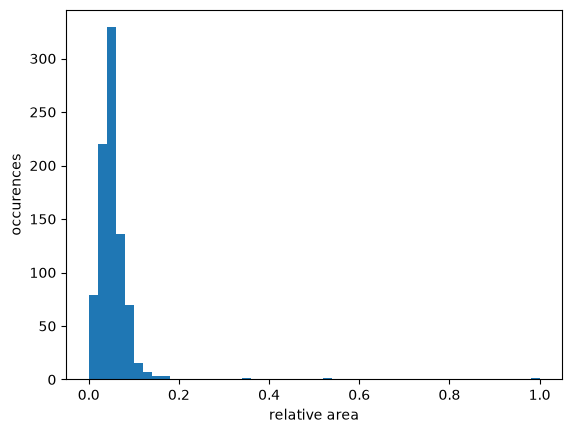

In [137]:
# Min-Max scaling of the variable 'area' (by hand)

from sklearn.preprocessing import MinMaxScaler, MaxAbsScaler, RobustScaler, StandardScaler
scaler = MinMaxScaler()
df4['area_z'] = scaler.fit_transform(df4[['area']]).ravel()


# Histogram of the variable 'area' and 'area_scaled_minmax'
plt.hist(df4['area_z'], bins=50)

# Set the y-axis range for each subplot and add labels
plt.xlabel("relative area")
plt.ylabel("occurences")

# Display the plot


#### scikit-learn version

In [ ]:
# Min-Max scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Max-Absolute Scaling

#### By hand

In [ ]:
# Max-Absolute scaling of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_max_abs'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [ ]:
# Max-Absolute scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Robust Scaling

#### By hand

In [ ]:
# Robust scaling of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_robust'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [ ]:
# Robust scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


## Standardization

### Z-score Normalization

#### By hand

In [ ]:
# Z-score Normalization of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_z'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [ ]:
# Z-score Normalization of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly


# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)


## Transformation

### Log-Transformation

In [ ]:
# Log-Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_log'


# Set the y-axis range for each subplot and add labels


# Display the plot


In [ ]:
# SQRT-Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_sqrt'


# Set the y-axis range for each subplot and add labels


# Display the plot


### Box-Cox Transformation

In [ ]:
# Import the boxcox function from scipy


# Box-Cox Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_boxcox'


# Set the y-axis range for each subplot and add labels


# Display the plot


## Combining & organizing data

### Reading rental apartment data with geocoded addresses

In [ ]:
# Meaning of variables
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)


# Show data


### Join geo-information to rental apartment data using .merge()

In [ ]:
# Merge geo-information to the apartment data (the key is 'web-scraper-order')


# Show data


### Reading municipality-level data

In [ ]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees

# Read municipality-level data from the .xlsx file


# Show data


### Join municipality data to rental apartment data using .merge()

In [ ]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')


# Show data


## Sorting data

In [ ]:
# Sorting data by 'price' and 'area' with highest price above (ascending=False)


# Show data


## Reshaping data

### Reshaping data using .stack() and .unstack()

In [ ]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .stack()


# Reshape the data back using .unstack()


### Reshaping data using .melt()

In [ ]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .melt()


### Pivoting data using .pivot_table()

In [ ]:
# Create a pivot table with the mean values per number of rooms


# Format the values to 2 decimal places with trailing zeros


# Display the pivot table


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')